In [ ]:
# Hosted D2L setup: fetch the exact helper module used to build this notebook.
from pathlib import Path
from urllib.request import urlretrieve
from importlib.metadata import PackageNotFoundError, version
import importlib.util, os, subprocess, sys

required = ['numpy', 'pandas', 'matplotlib', 'requests', 'scipy', 'pillow', 'regex', 'jax', 'jaxlib', 'flax', 'optax', 'orbax-checkpoint', 'tensorflow', 'protobuf', 'ml-dtypes']
imports = {'pillow': 'PIL', 'orbax-checkpoint': 'orbax', 'protobuf': 'google.protobuf', 'ml-dtypes': 'ml_dtypes'}
pinned = {'jax': ('0.12.0.1', 'jax==0.12.0.1', 'jax[cuda12]==0.12.0.1', 'exact'), 'jaxlib': ('0.12.0.1', 'jaxlib==0.12.0.1', 'jaxlib==0.12.0.1', 'exact'), 'flax': ('0.12.12', 'flax==0.12.12', 'flax==0.12.12', 'exact'), 'optax': ('0.2.8', 'optax==0.2.8', 'optax==0.2.8', 'exact'), 'orbax-checkpoint': ('0.12.0', 'orbax-checkpoint==0.12.0', 'orbax-checkpoint==0.12.0', 'exact')}
fallbacks = {'tensorflow': 'tensorflow==2.21.0', 'protobuf': 'protobuf==7.34.1', 'ml-dtypes': 'ml-dtypes==0.5.4'}
device = os.environ.get("D2L_HOSTED_DEVICE", "auto").lower()
if device not in ("auto", "cpu", "gpu"):
    raise ValueError(f"Invalid D2L_HOSTED_DEVICE={device!r}")
if device == "auto":
    try:
        gpu = (Path("/dev/nvidia0").exists() or
               subprocess.run(["nvidia-smi", "-L"], capture_output=True,
                              timeout=5).returncode == 0)
    except (FileNotFoundError, subprocess.SubprocessError):
        gpu = False
else:
    gpu = device == "gpu"
if not gpu:
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")
    os.environ.setdefault("JAX_PLATFORMS", "cpu")
tensorflow_version = None
if 'jax' in ("tensorflow", "jax"):
    try:
        tensorflow_version = version("tensorflow")
    except PackageNotFoundError:
        pass
# Colab's CPU image currently carries a CUDA-enabled TensorFlow wheel. Its
# first ordinary tensor operation probes CUDA and emits an error-level cuInit
# diagnostic. JAX notebooks also use TensorFlow for data loading, so overlay
# the matching CPU build in both CPU variants. Keep the provider's
# ``tensorflow`` distribution metadata: other preinstalled Colab packages
# depend on that distribution name, while both wheels expose the same module.
if not gpu and 'jax' in ("tensorflow", "jax"):
    try:
        tensorflow_cpu_version = version("tensorflow-cpu")
    except PackageNotFoundError:
        tensorflow_cpu_version = None
    if (tensorflow_version is not None and
            tensorflow_cpu_version != tensorflow_version):
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", "--no-deps",
            f"tensorflow-cpu=={tensorflow_version}",
        ])
if "tf-keras" in fallbacks and tensorflow_version is not None:
    fallbacks["tf-keras"] = f"tf-keras=={tensorflow_version}"
missing = []
for package in required:
    if package in pinned:
        wanted, cpu_requirement, gpu_requirement, match = pinned[package]
        requirement = gpu_requirement if gpu else cpu_requirement
        if requirement is None:  # a GPU-only package on a CPU runtime
            continue
        try:
            installed = version(package)
        except PackageNotFoundError:
            installed = None
        actual = (installed.split("+", 1)[0]
                  if installed is not None and match == "public" else installed)
        if actual != wanted:
            missing.append(requirement)
    elif importlib.util.find_spec(imports.get(package, package)) is None:
        missing.append(fallbacks.get(package, package))
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

mismatched = []
for package, (wanted, cpu_requirement, _, match) in pinned.items():
    if not gpu and cpu_requirement is None:
        continue
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    actual = (installed.split("+", 1)[0]
              if installed is not None and match == "public" else installed)
    if actual != wanted:
        mismatched.append(f"{package}={installed!r} (expected {wanted})")
if mismatched:
    raise RuntimeError("Hosted runtime setup failed: " + ", ".join(mismatched))

root = Path(".d2l-hosted") / "46d487bb9b699b97c7c5fc5edd866e4d2ad7919b"
package = root / "d2l"
package.mkdir(parents=True, exist_ok=True)
base = "https://raw.githubusercontent.com/smolix/d2l-neu/46d487bb9b699b97c7c5fc5edd866e4d2ad7919b/d2l"
for name in ('__init__.py', 'jax.py'):
    target = package / name
    if not target.exists():
        urlretrieve(f"{base}/{name}", target)
if str(root.resolve()) not in sys.path:
    sys.path.insert(0, str(root.resolve()))
pythonpath = os.environ.get("PYTHONPATH", "").split(os.pathsep)
if str(root.resolve()) not in pythonpath:
    os.environ["PYTHONPATH"] = os.pathsep.join(
        [str(root.resolve()), *[entry for entry in pythonpath if entry]]
    )


# Hyperparameter Optimization API

Before we dive into the methodology, we will first discuss a basic code
structure that allows us to efficiently implement various HPO algorithms. In
general, all HPO algorithms considered here need to implement two decision
making primitives, *searching* and *scheduling*. First, they need to sample new
hyperparameter configurations, which often involves some kind of search over the
configuration space. Second, for each configuration, an HPO algorithm needs to
schedule its evaluation and decide how many resources to allocate for it. Once
we start to evaluate a configuration, we will refer to it as a *trial*. We map
these decisions to two classes, `HPOSearcher` and `HPOScheduler`. On top of that,
we also provide a `HPOTuner` class that executes the optimization process.

This concept of scheduler and searcher is also implemented in popular HPO
libraries, such as Syne Tune [@salinas-automl22], Ray Tune
[@liaw-arxiv18] or Optuna [@akiba-sigkdd19].

In [1]:
import math
import numpy as np
import jax
from jax import numpy as jnp
from flax import nnx
import optax
from d2l import jax as d2l

In [2]:
import time
from scipy import stats

## Searcher

Below we define a base class for searchers, which provides a new candidate
configuration through the `sample_configuration` function. A simple way to
implement this function would be to sample configurations uniformly at random,
as we did for random search in that section. More sophisticated
algorithms, such as Bayesian optimization, will make these
decisions based on the performance of previous trials. As a result, these
algorithms are able to sample more promising candidates over time. We add the
`update` function in order to update the history of previous trials, which can
then be exploited to improve our sampling distribution.

In [3]:
class HPOSearcher(d2l.HyperParameters):
    def sample_configuration(self) -> dict:
        raise NotImplementedError

    def update(self, config: dict, error: float, additional_info=None):
        pass

The following code shows how to implement our random search optimizer from the
previous section in this API. As a slight extension, we allow the user to
prescribe the first configuration to be evaluated via `initial_config`, while
subsequent ones are drawn at random.

In [4]:
class RandomSearcher(HPOSearcher):
    def __init__(self, config_space: dict, initial_config=None):
        self.save_hyperparameters()

    def sample_configuration(self) -> dict:
        if self.initial_config is not None:
            result = self.initial_config
            self.initial_config = None
        else:
            result = {
                name: domain.rvs()
                for name, domain in self.config_space.items()
            }
        return result

## Scheduler

Beyond sampling configurations for new trials, we also need to decide when and
for how long to run a trial. In practice, all these decisions are done by the
`HPOScheduler`, which delegates the choice of new configurations to a
`HPOSearcher`. The `suggest` method is called whenever some resource for training
becomes available. Apart from invoking `sample_configuration` of a searcher, it
may also decide upon parameters like `max_epochs` (i.e., how long to train the
model for). The `update` method is called whenever a trial returns a new
observation.

In [5]:
class HPOScheduler(d2l.HyperParameters):
    def suggest(self) -> dict:
        raise NotImplementedError
    
    def update(self, config: dict, error: float, info=None):
        raise NotImplementedError

To implement random search, but also other HPO algorithms, we only need a basic
scheduler that schedules a new configuration every time new resources become
available.

In [6]:
class BasicScheduler(HPOScheduler):
    def __init__(self, searcher: HPOSearcher):
        self.save_hyperparameters()

    def suggest(self) -> dict:
        return self.searcher.sample_configuration()

    def update(self, config: dict, error: float, info=None):
        self.searcher.update(config, error, additional_info=info)

## Tuner

Finally, we need a component that runs the scheduler/searcher and does some
book-keeping of the results. The following code implements a sequential
execution of the HPO trials that evaluates one training job after the next and
will serve as a basic example. We will later use *Syne Tune* for more scalable
distributed HPO cases.

In [7]:
class HPOTuner(d2l.HyperParameters):
    def __init__(self, scheduler: HPOScheduler, objective: callable):
        self.save_hyperparameters()
        self.incumbent, self.incumbent_error = None, None  # Best so far
        self.incumbent_trajectory, self.records = [], []
        self.cumulative_runtime, self.current_runtime = [], 0

    def run(self, number_of_trials):
        for i in range(number_of_trials):
            start_time = time.time()
            config = self.scheduler.suggest()
            print(f"Trial {i}: " + ", ".join(  # Floats to 4 significant digits
                f"{k} = {v:.4g}" if isinstance(v, float) else f"{k} = {v}"
                for k, v in config.items()))
            error = float(self.objective(**config))
            self.scheduler.update(config, error)
            runtime = time.time() - start_time
            self.bookkeeping(config, error, runtime)
            print(f"    error = {error:.4f}, runtime = {runtime:.1f} s")

## Bookkeeping the Performance of HPO Algorithms

With any HPO algorithm, we are mostly interested in the best performing
configuration (called *incumbent*) and its validation error after a given 
wall-clock time. This is why we track `runtime` per iteration, which includes
both the time to run an evaluation (call of `objective`) and the time to
make a decision (call of `scheduler.suggest`). In the sequel, we will plot
`cumulative_runtime` against `incumbent_trajectory` in  order to visualize the
*any-time performance* of the HPO algorithm defined in  terms of `scheduler`
(and `searcher`). This allows us to quantify not only how well the configuration
found by an optimizer works, but also how quickly an optimizer is able to find it.

In [8]:
@d2l.add_to_class(HPOTuner)
def bookkeeping(self, config: dict, error: float, runtime: float):
    self.records.append({"config": config, "error": error, "runtime": runtime})
    # Check if the last hyperparameter configuration performs better 
    # than the incumbent
    if self.incumbent is None or self.incumbent_error > error:
        self.incumbent = config
        self.incumbent_error = error
    # Add current best observed performance to the optimization trajectory
    self.incumbent_trajectory.append(self.incumbent_error)
    # Update runtime
    self.current_runtime += runtime
    self.cumulative_runtime.append(self.current_runtime)

## Example: Optimizing the Hyperparameters of a Convolutional Neural Network

We now use our new implementation of random search to optimize the
*batch size* and *learning rate* of the `LeNet` convolutional neural network
from that section. We begin by defining the objective function, which
will once more be validation error.

In [9]:
def hpo_objective_lenet(learning_rate, batch_size, max_epochs=10):
    model = d2l.LeNet(lr=learning_rate, num_classes=10)
    trainer = d2l.HPOTrainer(max_epochs=max_epochs, num_gpus=1)
    data = d2l.FashionMNIST(batch_size=batch_size)
    trainer.fit(model=model, data=data)
    validation_error = trainer.validation_error()
    return validation_error

We also need to define the configuration space. The first configuration to
be evaluated is a common default for SGD, a learning rate of 0.1 and
minibatches of 128.

In [10]:
config_space = {
    "learning_rate": stats.loguniform(1e-2, 1),
    "batch_size": stats.randint(32, 256),
}
initial_config = {
    "learning_rate": 0.1,
    "batch_size": 128,
}

Now we can start our random search:

Trial 0: learning_rate = 0.1, batch_size = 128


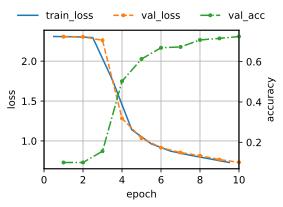

    error = 0.2755, runtime = 32.3 s
Trial 1: learning_rate = 0.2367, batch_size = 74


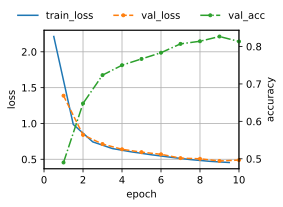

    error = 0.1866, runtime = 35.8 s
Trial 2: learning_rate = 0.05565, batch_size = 191


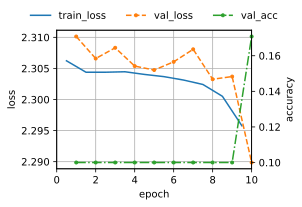

    error = 0.8292, runtime = 25.4 s
Trial 3: learning_rate = 0.1949, batch_size = 147


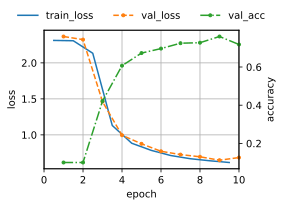

    error = 0.2819, runtime = 30.4 s
Trial 4: learning_rate = 0.02489, batch_size = 130


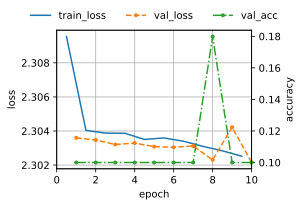

    error = 0.9000, runtime = 33.7 s


In [11]:
searcher = RandomSearcher(config_space, initial_config=initial_config)
scheduler = BasicScheduler(searcher=searcher)
tuner = HPOTuner(scheduler=scheduler, objective=hpo_objective_lenet)
tuner.run(number_of_trials=5)

Below we plot the optimization trajectory of the incumbent to get the any-time
performance of random search:

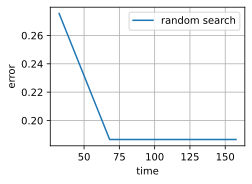

In [12]:
board = d2l.ProgressBoard(xlabel="time", ylabel="error")
for time_stamp, error in zip(
    tuner.cumulative_runtime, tuner.incumbent_trajectory
):
    board.draw(time_stamp, error, "random search")
board.show()

## Comparing HPO Algorithms

Just as with training algorithms or model architectures, it is important to
understand how to best compare different HPO algorithms. Each HPO run depends
on two major sources of randomness: the random effects of the training process,
such as random weight initialization or mini-batch ordering, and the intrinsic
randomness of the HPO algorithm itself, such as the random sampling of random
search. Hence, when comparing different algorithms, it is crucial to run each
experiment several times and report statistics, such as mean or median, across
a population of multiple repetitions of an algorithm based on different seeds
of the random number generator.

To illustrate this, we compare random search (see that section) and Bayesian
optimization [@snoek-nips12] on tuning the hyperparameters of a feed-forward
neural network. Each algorithm was evaluated
$50$ times with a different random seed. The solid line indicates the average
performance of the incumbent across these $50$ repetitions and the dashed line
the standard deviation. We can see that random search and Bayesian optimization
perform roughly the same up to ~1000 seconds, but Bayesian optimization can
make use of the past observation to identify better configurations and thus
quickly outperforms random search afterwards.


![Example any-time performance plot to compare two algorithms A and B.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/example_anytime_performance.svg)

## Summary

This section laid out a simple, yet flexible interface to implement various HPO
algorithms that we will look at in this chapter. Similar interfaces can be found
in popular open-source HPO frameworks. We also looked at how we can compare HPO
algorithms, and potential pitfalls one needs to be aware of. 

## Exercises

1. The goal of this exercise is to implement the objective function for a slightly more challenging HPO problem, and to run more realistic experiments. We will use the two hidden layer MLP `DropoutMLP` implemented in that section.
    1. Code up the objective function, which should depend on all hyperparameters of the model and `batch_size`. Use `max_epochs=50`. GPUs do not help here, so `num_gpus=0`. Hint: Modify `hpo_objective_lenet`.
    2. Choose a sensible search space, where `num_hiddens_1`, `num_hiddens_2` are integers in $[8, 1024]$, and dropout values lie in $[0, 0.95]$, while `batch_size` lies in $[16, 384]$. Provide code for `config_space`, using sensible distributions from `scipy.stats`.
    3. Run random search on this example with `number_of_trials=20` and plot the results. Make sure to first evaluate the default configuration of that section, which is `initial_config = {'num_hiddens_1': 256, 'num_hiddens_2': 256, 'dropout_1': 0.5, 'dropout_2': 0.5, 'lr': 0.1, 'batch_size': 256}`.
2. In this exercise, you will implement a new searcher (subclass of `HPOSearcher`) which makes decisions based on past data. It depends on parameters `probab_local`, `num_init_random`. Its `sample_configuration` method works as follows. For the first `num_init_random` calls, do the same as `RandomSearcher.sample_configuration`. Otherwise, with probability `1 - probab_local`, do the same as `RandomSearcher.sample_configuration`. Otherwise, pick the configuration which attained the smallest validation error so far, select one of its hyperparameters at random, and sample its value randomly like in `RandomSearcher.sample_configuration`, but leave all other values the same. Return this configuration, which is identical to the best configuration so far, except in this one hyperparameter.
    1. Code up this new `LocalSearcher`. Hint: Your searcher requires `config_space` as argument at construction. Feel free to use a member of type `RandomSearcher`. You will also have to implement the `update` method.
    2. Re-run the experiment from the previous exercise, but using your new searcher instead of `RandomSearcher`. Experiment with different values for `probab_local`, `num_init_random`. However, note that a proper comparison between different HPO methods requires repeating experiments several times, and ideally considering a number of benchmark tasks.
3. `HPOTuner` passes a configuration to `objective` and receives a single validation error once training has finished. Consider the *median stopping rule*: stop a trial after epoch $r$ if its validation error at epoch $r$ is larger than the median of the errors that earlier trials had at epoch $r$.
    1. Which decisions in this rule belong to the searcher and which to the scheduler?
    2. Explain why the rule cannot be implemented with `HPOTuner`, `HPOScheduler` and `hpo_objective_lenet` as written. List the changes to the interface that would make it possible: what the objective must report and when, which method of the scheduler the tuner must call and when, and how the tuner learns that a trial is to be stopped.
    3. A stopped trial never reports an error at `max_epochs`. Should `bookkeeping` allow such a trial to become the incumbent? Sketch two learning curves for which the answer matters.
4. `HPOTuner` records the runtime of every trial in `tuner.records`. Run the LeNet example for 10 trials with `functools.partial(hpo_objective_lenet, max_epochs=3)` as the objective.
    1. Plot the runtime of each trial against its batch size $B$, fit $\textrm{runtime} \approx a + b/B$ by least squares, and report $a$ and $b$. Which parts of a trial do the two terms account for? Why can the first trial be an outlier?
    2. the figure measures cost in wall-clock time rather than in number of trials. Suppose two searchers find configurations of the same quality, but one of them prefers small batch sizes. How do their any-time curves differ? When is wall-clock time the better measure of cost for comparing searchers, and when is the number of trials?
5. The section asks for repeated runs with different random seeds before HPO algorithms are compared. To keep the runs short, use `functools.partial(hpo_objective_lenet, max_epochs=3)` as the objective.
    1. Run random search with `HPOTuner` three times for 5 trials each, seeding NumPy's global random number generator, which `scipy.stats` uses for sampling, differently each time. The three runs record their incumbent errors at different values of `cumulative_runtime`. Write a function that evaluates each `incumbent_trajectory` as a step function on a common grid of times and returns the mean and the standard deviation across runs, and plot both as in the figure.
    2. The spread across runs has two sources: the configurations that the searcher samples and the randomness of training. Design an experiment with the same code that measures the second source alone, run it, and report which of the two sources dominates the spread of the final incumbent error.
    3. Let $\sigma$ be the standard deviation of the final incumbent error that you measured. How many runs per algorithm are needed before a difference of 0.005 between the mean final errors of two algorithms is twice the standard error of that difference?

[Discussions](https://d2l.discourse.group/t/12092)